Lectura inicial: 6628ITR
Matrícula final: 6628LTR


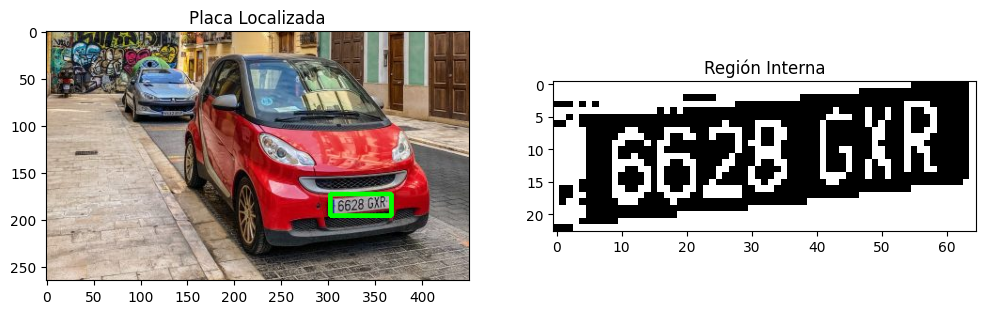

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.neighbors import KNeighborsClassifier
from skimage.feature import hog


SEED = 42
np.random.seed(SEED)
random.seed(SEED)
clases = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def normalizar_char(img):
    h, w = img.shape
    scale = 18 / max(h, w)
    img_resized = cv2.resize(img, (int(w * scale), int(h * scale)))

    canvas = np.zeros((20, 20), dtype=np.uint8)
    y_off = (20 - img_resized.shape[0]) // 2
    x_off = (20 - img_resized.shape[1]) // 2
    canvas[y_off:y_off + img_resized.shape[0], x_off:x_off + img_resized.shape[1]] = img_resized
    return canvas

def extraer_hog(img_20x20):
    return hog(img_20x20, orientations=9, pixels_per_cell=(4, 4),
               cells_per_block=(2, 2), visualize=False)


def generar_dataset_entrenamiento():
    X, y = [], []
    fuentes = [
        cv2.FONT_HERSHEY_SIMPLEX,
        cv2.FONT_HERSHEY_DUPLEX,
        cv2.FONT_HERSHEY_PLAIN
    ]

    for i, char in enumerate(clases):
        for _ in range(300):
            img_char = np.zeros((40, 40), dtype=np.uint8)
            fuente = random.choice(fuentes)

            off_x, off_y = np.random.randint(5, 15), np.random.randint(25, 35)
            escala = 0.8 + (np.random.rand() * 0.4)

            cv2.putText(img_char, char, (off_x, off_y), fuente, escala, 255, 2)

            cnts, _ = cv2.findContours(img_char, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if cnts:
                bx, by, bw, bh = cv2.boundingRect(cnts[0])
                char_crop = img_char[by:by+bh, bx:bx+bw]
                char_norm = normalizar_char(char_crop)

                if np.random.rand() > 0.5:
                    char_norm = cv2.GaussianBlur(char_norm, (3, 3), 0)

                X.append(extraer_hog(char_norm))
                y.append(i)

    return np.array(X), np.array(y)

X_train, y_train = generar_dataset_entrenamiento()

knn = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn.fit(X_train, y_train)

def corregir_formato_espana(texto_sucio):
    a_num = {'Z':'2', 'S':'5', 'B':'8', 'I':'1', 'L':'1', 'O':'0', 'D':'0', 'G':'6', 'E':'3', 'A':'4', 'P':'9'}
    a_let = {'2':'Z', '5':'S', '8':'B', '1':'L', '0':'D', '3':'P', '4':'H', '6':'G', '9':'P'}
    vocales_a_consonantes = {'A':'H', 'E':'P', 'I':'L', 'O':'D', 'U':'V'}

    if len(texto_sucio) < 7: return texto_sucio
    texto = texto_sucio[-7:]
    res = list(texto)

    for i in range(7):
        if i < 4:
            if not res[i].isdigit(): res[i] = a_num.get(res[i], '0')
        else:
            if res[i].isdigit(): res[i] = a_let.get(res[i], 'X')
            if res[i] in "AEIOU": res[i] = vocales_a_consonantes.get(res[i], 'X')
    return "".join(res)

def ejecutar_matridetector(archivo):
    img = cv2.imread(archivo)
    if img is None: return print("Error: No se encuentra la imagen.")

    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    suavizada = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suavizada, 50, 200)

    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    posibles_placas = []
    h_img, w_img = gris.shape

    for c in contornos:
        x, y, w, h = cv2.boundingRect(c)
        ratio = w / h
        if 2.0 < ratio < 6.0 and (w_img * 0.05 < w < w_img * 0.4):
            roi = gris[y:y+h, x:x+w]
            _, bin_roi = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

            internos, _ = cv2.findContours(bin_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            caracteres_validos = 0
            for ci in internos:
                ix, iy, iw, ih = cv2.boundingRect(ci)
                i_ratio = iw / ih
                if (ih > h * 0.45) and (0.1 < i_ratio < 0.9):
                    caracteres_validos += 1

            posibles_placas.append({
                'box': (x, y, w, h),
                'score': caracteres_validos,
                'bin': bin_roi
            })

    posibles_placas.sort(key=lambda p: abs(p['score'] - 7))

    if posibles_placas and posibles_placas[0]['score'] > 3:
        mejor_placa = posibles_placas[0]
        x, y, w, h = mejor_placa['box']
        placa_binaria = mejor_placa['bin']

        img_viz = img.copy()
        cv2.rectangle(img_viz, (x, y), (x + w, y + h), (0, 255, 0), 3)

        cnts, _ = cv2.findContours(placa_binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        candidatos_ocr = []
        for cc in cnts:
            cx, cy, cw, ch = cv2.boundingRect(cc)
            if (ch > h * 0.45) and (0.2 < (cw/ch) < 0.9):
                char_img = normalizar_char(placa_binaria[cy:cy+ch, cx:cx+cw])
                feat = extraer_hog(char_img).reshape(1, -1)
                pred = clases[knn.predict(feat)[0]]
                candidatos_ocr.append((cx, pred))

        candidatos_ocr.sort(key=lambda x: x[0])
        lectura_inicial = "".join([c[1] for c in candidatos_ocr])
        resultado = corregir_formato_espana(lectura_inicial)

        print(f"Lectura inicial: {lectura_inicial}")
        print(f"Matrícula final: {resultado}")

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img_viz, cv2.COLOR_BGR2RGB)); plt.title("Placa Localizada")
        plt.subplot(1, 2, 2); plt.imshow(placa_binaria, cmap='gray'); plt.title("Región Interna")
        plt.show()
    else:
        print("No se encontró ninguna placa válida (los candidatos no parecen tener letras).")

ejecutar_matridetector('imagen1.jpeg')


Lectura inicial: I0724HPH
Matrícula final: 0724HPH


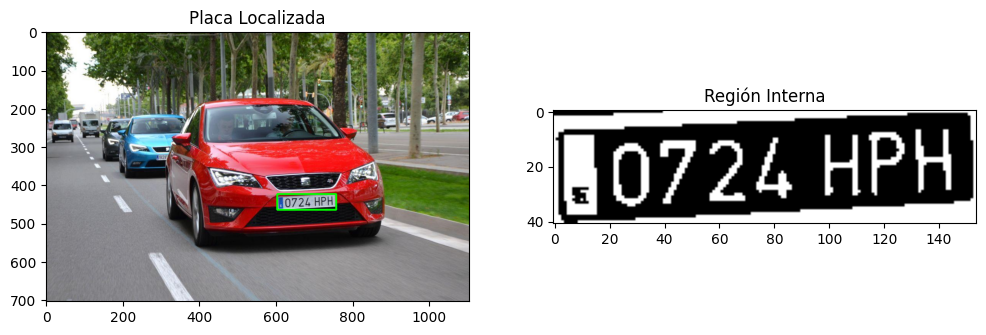

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.neighbors import KNeighborsClassifier
from skimage.feature import hog


SEED = 42
np.random.seed(SEED)
random.seed(SEED)
clases = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def normalizar_char(img):
    h, w = img.shape
    scale = 18 / max(h, w)
    img_resized = cv2.resize(img, (int(w * scale), int(h * scale)))

    canvas = np.zeros((20, 20), dtype=np.uint8)
    y_off = (20 - img_resized.shape[0]) // 2
    x_off = (20 - img_resized.shape[1]) // 2
    canvas[y_off:y_off + img_resized.shape[0], x_off:x_off + img_resized.shape[1]] = img_resized
    return canvas

def extraer_hog(img_20x20):
    return hog(img_20x20, orientations=9, pixels_per_cell=(4, 4),
               cells_per_block=(2, 2), visualize=False)


def generar_dataset_entrenamiento():
    X, y = [], []
    fuentes = [
        cv2.FONT_HERSHEY_SIMPLEX,
        cv2.FONT_HERSHEY_DUPLEX,
        cv2.FONT_HERSHEY_PLAIN
    ]

    for i, char in enumerate(clases):
        for _ in range(300):
            img_char = np.zeros((40, 40), dtype=np.uint8)
            fuente = random.choice(fuentes)

            off_x, off_y = np.random.randint(5, 15), np.random.randint(25, 35)
            escala = 0.8 + (np.random.rand() * 0.4)

            cv2.putText(img_char, char, (off_x, off_y), fuente, escala, 255, 2)

            cnts, _ = cv2.findContours(img_char, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if cnts:
                bx, by, bw, bh = cv2.boundingRect(cnts[0])
                char_crop = img_char[by:by+bh, bx:bx+bw]
                char_norm = normalizar_char(char_crop)

                if np.random.rand() > 0.5:
                    char_norm = cv2.GaussianBlur(char_norm, (3, 3), 0)

                X.append(extraer_hog(char_norm))
                y.append(i)

    return np.array(X), np.array(y)

X_train, y_train = generar_dataset_entrenamiento()

knn = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn.fit(X_train, y_train)

def corregir_formato_espana(texto_sucio):
    a_num = {'Z':'2', 'S':'5', 'B':'8', 'I':'1', 'L':'1', 'O':'0', 'D':'0', 'G':'6', 'E':'3', 'A':'4', 'P':'9'}
    a_let = {'2':'Z', '5':'S', '8':'B', '1':'L', '0':'D', '3':'P', '4':'H', '6':'G', '9':'P'}
    vocales_a_consonantes = {'A':'H', 'E':'P', 'I':'L', 'O':'D', 'U':'V'}

    if len(texto_sucio) < 7: return texto_sucio
    texto = texto_sucio[-7:]
    res = list(texto)

    for i in range(7):
        if i < 4:
            if not res[i].isdigit(): res[i] = a_num.get(res[i], '0')
        else:
            if res[i].isdigit(): res[i] = a_let.get(res[i], 'X')
            if res[i] in "AEIOU": res[i] = vocales_a_consonantes.get(res[i], 'X')
    return "".join(res)

def ejecutar_matridetector(archivo):
    img = cv2.imread(archivo)
    if img is None: return print("Error: No se encuentra la imagen.")

    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    suavizada = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suavizada, 50, 200)

    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    posibles_placas = []
    h_img, w_img = gris.shape

    for c in contornos:
        x, y, w, h = cv2.boundingRect(c)
        ratio = w / h
        if 2.0 < ratio < 6.0 and (w_img * 0.05 < w < w_img * 0.4):
            roi = gris[y:y+h, x:x+w]
            _, bin_roi = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

            internos, _ = cv2.findContours(bin_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            caracteres_validos = 0
            for ci in internos:
                ix, iy, iw, ih = cv2.boundingRect(ci)
                i_ratio = iw / ih
                if (ih > h * 0.45) and (0.1 < i_ratio < 0.9):
                    caracteres_validos += 1

            posibles_placas.append({
                'box': (x, y, w, h),
                'score': caracteres_validos,
                'bin': bin_roi
            })

    posibles_placas.sort(key=lambda p: abs(p['score'] - 7))

    if posibles_placas and posibles_placas[0]['score'] > 3:
        mejor_placa = posibles_placas[0]
        x, y, w, h = mejor_placa['box']
        placa_binaria = mejor_placa['bin']

        img_viz = img.copy()
        cv2.rectangle(img_viz, (x, y), (x + w, y + h), (0, 255, 0), 3)

        cnts, _ = cv2.findContours(placa_binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        candidatos_ocr = []
        for cc in cnts:
            cx, cy, cw, ch = cv2.boundingRect(cc)
            if (ch > h * 0.45) and (0.2 < (cw/ch) < 0.9):
                char_img = normalizar_char(placa_binaria[cy:cy+ch, cx:cx+cw])
                feat = extraer_hog(char_img).reshape(1, -1)
                pred = clases[knn.predict(feat)[0]]
                candidatos_ocr.append((cx, pred))

        candidatos_ocr.sort(key=lambda x: x[0])
        lectura_inicial = "".join([c[1] for c in candidatos_ocr])
        resultado = corregir_formato_espana(lectura_inicial)

        print(f"Lectura inicial: {lectura_inicial}")
        print(f"Matrícula final: {resultado}")

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img_viz, cv2.COLOR_BGR2RGB)); plt.title("Placa Localizada")
        plt.subplot(1, 2, 2); plt.imshow(placa_binaria, cmap='gray'); plt.title("Región Interna")
        plt.show()
    else:
        print("No se encontró ninguna placa válida (los candidatos no parecen tener letras).")

ejecutar_matridetector('imagen2.jpeg')

Lectura inicial: 9245LCX
Matrícula final: 9245LCX


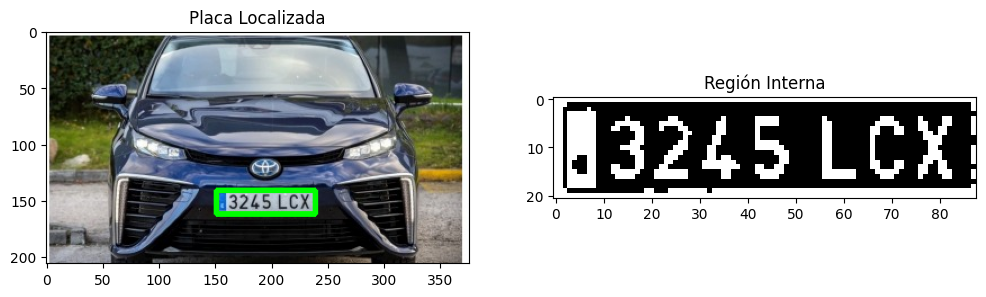

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.neighbors import KNeighborsClassifier
from skimage.feature import hog


SEED = 42
np.random.seed(SEED)
random.seed(SEED)
clases = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def normalizar_char(img):
    h, w = img.shape
    scale = 18 / max(h, w)
    img_resized = cv2.resize(img, (int(w * scale), int(h * scale)))

    canvas = np.zeros((20, 20), dtype=np.uint8)
    y_off = (20 - img_resized.shape[0]) // 2
    x_off = (20 - img_resized.shape[1]) // 2
    canvas[y_off:y_off + img_resized.shape[0], x_off:x_off + img_resized.shape[1]] = img_resized
    return canvas

def extraer_hog(img_20x20):
    return hog(img_20x20, orientations=9, pixels_per_cell=(4, 4),
               cells_per_block=(2, 2), visualize=False)


def generar_dataset_entrenamiento():
    X, y = [], []
    fuentes = [
        cv2.FONT_HERSHEY_SIMPLEX,
        cv2.FONT_HERSHEY_DUPLEX,
        cv2.FONT_HERSHEY_PLAIN
    ]

    for i, char in enumerate(clases):
        for _ in range(300):
            img_char = np.zeros((40, 40), dtype=np.uint8)
            fuente = random.choice(fuentes)

            off_x, off_y = np.random.randint(5, 15), np.random.randint(25, 35)
            escala = 0.8 + (np.random.rand() * 0.4)

            cv2.putText(img_char, char, (off_x, off_y), fuente, escala, 255, 2)

            cnts, _ = cv2.findContours(img_char, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if cnts:
                bx, by, bw, bh = cv2.boundingRect(cnts[0])
                char_crop = img_char[by:by+bh, bx:bx+bw]
                char_norm = normalizar_char(char_crop)

                if np.random.rand() > 0.5:
                    char_norm = cv2.GaussianBlur(char_norm, (3, 3), 0)

                X.append(extraer_hog(char_norm))
                y.append(i)

    return np.array(X), np.array(y)

X_train, y_train = generar_dataset_entrenamiento()

knn = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn.fit(X_train, y_train)

def corregir_formato_espana(texto_sucio):
    a_num = {'Z':'2', 'S':'5', 'B':'8', 'I':'1', 'L':'1', 'O':'0', 'D':'0', 'G':'6', 'E':'3', 'A':'4', 'P':'9'}
    a_let = {'2':'Z', '5':'S', '8':'B', '1':'L', '0':'D', '3':'P', '4':'H', '6':'G', '9':'P'}
    vocales_a_consonantes = {'A':'H', 'E':'P', 'I':'L', 'O':'D', 'U':'V'}

    if len(texto_sucio) < 7: return texto_sucio
    texto = texto_sucio[-7:]
    res = list(texto)

    for i in range(7):
        if i < 4:
            if not res[i].isdigit(): res[i] = a_num.get(res[i], '0')
        else:
            if res[i].isdigit(): res[i] = a_let.get(res[i], 'X')
            if res[i] in "AEIOU": res[i] = vocales_a_consonantes.get(res[i], 'X')
    return "".join(res)

def ejecutar_matridetector(archivo):
    img = cv2.imread(archivo)
    if img is None: return print("Error: No se encuentra la imagen.")

    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    suavizada = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suavizada, 50, 200)

    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    posibles_placas = []
    h_img, w_img = gris.shape

    for c in contornos:
        x, y, w, h = cv2.boundingRect(c)
        ratio = w / h
        if 2.0 < ratio < 6.0 and (w_img * 0.05 < w < w_img * 0.4):
            roi = gris[y:y+h, x:x+w]
            _, bin_roi = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

            internos, _ = cv2.findContours(bin_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            caracteres_validos = 0
            for ci in internos:
                ix, iy, iw, ih = cv2.boundingRect(ci)
                i_ratio = iw / ih
                if (ih > h * 0.45) and (0.1 < i_ratio < 0.9):
                    caracteres_validos += 1

            posibles_placas.append({
                'box': (x, y, w, h),
                'score': caracteres_validos,
                'bin': bin_roi
            })

    posibles_placas.sort(key=lambda p: abs(p['score'] - 7))

    if posibles_placas and posibles_placas[0]['score'] > 3:
        mejor_placa = posibles_placas[0]
        x, y, w, h = mejor_placa['box']
        placa_binaria = mejor_placa['bin']

        img_viz = img.copy()
        cv2.rectangle(img_viz, (x, y), (x + w, y + h), (0, 255, 0), 3)

        cnts, _ = cv2.findContours(placa_binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        candidatos_ocr = []
        for cc in cnts:
            cx, cy, cw, ch = cv2.boundingRect(cc)
            if (ch > h * 0.45) and (0.2 < (cw/ch) < 0.9):
                char_img = normalizar_char(placa_binaria[cy:cy+ch, cx:cx+cw])
                feat = extraer_hog(char_img).reshape(1, -1)
                pred = clases[knn.predict(feat)[0]]
                candidatos_ocr.append((cx, pred))

        candidatos_ocr.sort(key=lambda x: x[0])
        lectura_inicial = "".join([c[1] for c in candidatos_ocr])
        resultado = corregir_formato_espana(lectura_inicial)

        print(f"Lectura inicial: {lectura_inicial}")
        print(f"Matrícula final: {resultado}")

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img_viz, cv2.COLOR_BGR2RGB)); plt.title("Placa Localizada")
        plt.subplot(1, 2, 2); plt.imshow(placa_binaria, cmap='gray'); plt.title("Región Interna")
        plt.show()
    else:
        print("No se encontró ninguna placa válida (los candidatos no parecen tener letras).")

ejecutar_matridetector('imagen3.jpeg')

Lectura inicial: 2801NLE
Matrícula final: 2801NLP


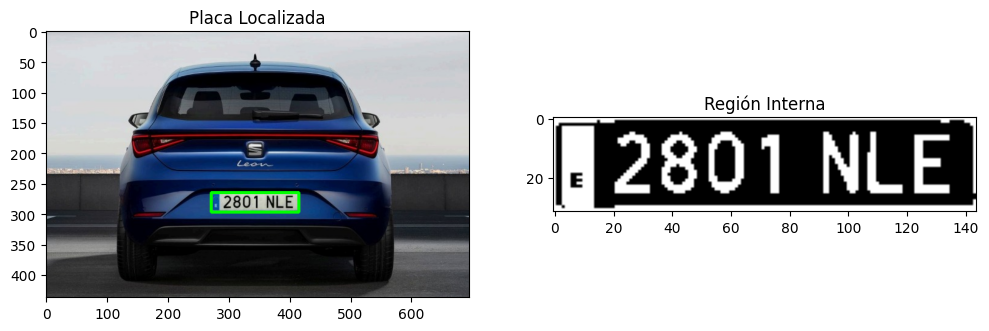

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.neighbors import KNeighborsClassifier
from skimage.feature import hog


SEED = 42
np.random.seed(SEED)
random.seed(SEED)
clases = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def normalizar_char(img):
    h, w = img.shape
    scale = 18 / max(h, w)
    img_resized = cv2.resize(img, (int(w * scale), int(h * scale)))

    canvas = np.zeros((20, 20), dtype=np.uint8)
    y_off = (20 - img_resized.shape[0]) // 2
    x_off = (20 - img_resized.shape[1]) // 2
    canvas[y_off:y_off + img_resized.shape[0], x_off:x_off + img_resized.shape[1]] = img_resized
    return canvas

def extraer_hog(img_20x20):
    return hog(img_20x20, orientations=9, pixels_per_cell=(4, 4),
               cells_per_block=(2, 2), visualize=False)


def generar_dataset_entrenamiento():
    X, y = [], []
    fuentes = [
        cv2.FONT_HERSHEY_SIMPLEX,
        cv2.FONT_HERSHEY_DUPLEX,
        cv2.FONT_HERSHEY_PLAIN
    ]

    for i, char in enumerate(clases):
        for _ in range(300):
            img_char = np.zeros((40, 40), dtype=np.uint8)
            fuente = random.choice(fuentes)

            off_x, off_y = np.random.randint(5, 15), np.random.randint(25, 35)
            escala = 0.8 + (np.random.rand() * 0.4)

            cv2.putText(img_char, char, (off_x, off_y), fuente, escala, 255, 2)

            cnts, _ = cv2.findContours(img_char, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if cnts:
                bx, by, bw, bh = cv2.boundingRect(cnts[0])
                char_crop = img_char[by:by+bh, bx:bx+bw]
                char_norm = normalizar_char(char_crop)

                if np.random.rand() > 0.5:
                    char_norm = cv2.GaussianBlur(char_norm, (3, 3), 0)

                X.append(extraer_hog(char_norm))
                y.append(i)

    return np.array(X), np.array(y)

X_train, y_train = generar_dataset_entrenamiento()

knn = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn.fit(X_train, y_train)

def corregir_formato_espana(texto_sucio):
    a_num = {'Z':'2', 'S':'5', 'B':'8', 'I':'1', 'L':'1', 'O':'0', 'D':'0', 'G':'6', 'E':'3', 'A':'4', 'P':'9'}
    a_let = {'2':'Z', '5':'S', '8':'B', '1':'L', '0':'D', '3':'P', '4':'H', '6':'G', '9':'P'}
    vocales_a_consonantes = {'A':'H', 'E':'P', 'I':'L', 'O':'D', 'U':'V'}

    if len(texto_sucio) < 7: return texto_sucio
    texto = texto_sucio[-7:]
    res = list(texto)

    for i in range(7):
        if i < 4:
            if not res[i].isdigit(): res[i] = a_num.get(res[i], '0')
        else:
            if res[i].isdigit(): res[i] = a_let.get(res[i], 'X')
            if res[i] in "AEIOU": res[i] = vocales_a_consonantes.get(res[i], 'X')
    return "".join(res)

def ejecutar_matridetector(archivo):
    img = cv2.imread(archivo)
    if img is None: return print("Error: No se encuentra la imagen.")

    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    suavizada = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suavizada, 50, 200)

    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    posibles_placas = []
    h_img, w_img = gris.shape

    for c in contornos:
        x, y, w, h = cv2.boundingRect(c)
        ratio = w / h
        if 2.0 < ratio < 6.0 and (w_img * 0.05 < w < w_img * 0.4):
            roi = gris[y:y+h, x:x+w]
            _, bin_roi = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

            internos, _ = cv2.findContours(bin_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            caracteres_validos = 0
            for ci in internos:
                ix, iy, iw, ih = cv2.boundingRect(ci)
                i_ratio = iw / ih
                if (ih > h * 0.45) and (0.1 < i_ratio < 0.9):
                    caracteres_validos += 1

            posibles_placas.append({
                'box': (x, y, w, h),
                'score': caracteres_validos,
                'bin': bin_roi
            })

    posibles_placas.sort(key=lambda p: abs(p['score'] - 7))

    if posibles_placas and posibles_placas[0]['score'] > 3:
        mejor_placa = posibles_placas[0]
        x, y, w, h = mejor_placa['box']
        placa_binaria = mejor_placa['bin']

        img_viz = img.copy()
        cv2.rectangle(img_viz, (x, y), (x + w, y + h), (0, 255, 0), 3)

        cnts, _ = cv2.findContours(placa_binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        candidatos_ocr = []
        for cc in cnts:
            cx, cy, cw, ch = cv2.boundingRect(cc)
            if (ch > h * 0.45) and (0.2 < (cw/ch) < 0.9):
                char_img = normalizar_char(placa_binaria[cy:cy+ch, cx:cx+cw])
                feat = extraer_hog(char_img).reshape(1, -1)
                pred = clases[knn.predict(feat)[0]]
                candidatos_ocr.append((cx, pred))

        candidatos_ocr.sort(key=lambda x: x[0])
        lectura_inicial = "".join([c[1] for c in candidatos_ocr])
        resultado = corregir_formato_espana(lectura_inicial)

        print(f"Lectura inicial: {lectura_inicial}")
        print(f"Matrícula final: {resultado}")

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img_viz, cv2.COLOR_BGR2RGB)); plt.title("Placa Localizada")
        plt.subplot(1, 2, 2); plt.imshow(placa_binaria, cmap='gray'); plt.title("Región Interna")
        plt.show()
    else:
        print("No se encontró ninguna placa válida (los candidatos no parecen tener letras).")

ejecutar_matridetector('imagen4.jpeg')

Lectura inicial: 0411KHT
Matrícula final: 0411KHT


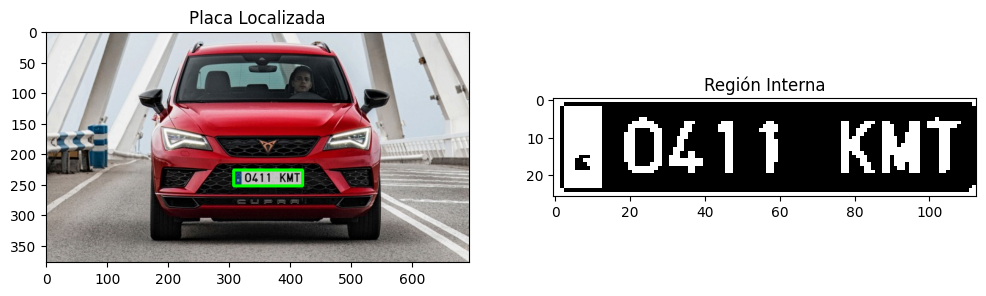

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.neighbors import KNeighborsClassifier
from skimage.feature import hog


SEED = 42
np.random.seed(SEED)
random.seed(SEED)
clases = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def normalizar_char(img):
    h, w = img.shape
    scale = 18 / max(h, w)
    img_resized = cv2.resize(img, (int(w * scale), int(h * scale)))

    canvas = np.zeros((20, 20), dtype=np.uint8)
    y_off = (20 - img_resized.shape[0]) // 2
    x_off = (20 - img_resized.shape[1]) // 2
    canvas[y_off:y_off + img_resized.shape[0], x_off:x_off + img_resized.shape[1]] = img_resized
    return canvas

def extraer_hog(img_20x20):
    return hog(img_20x20, orientations=9, pixels_per_cell=(4, 4),
               cells_per_block=(2, 2), visualize=False)


def generar_dataset_entrenamiento():
    X, y = [], []
    fuentes = [
        cv2.FONT_HERSHEY_SIMPLEX,
        cv2.FONT_HERSHEY_DUPLEX,
        cv2.FONT_HERSHEY_PLAIN
    ]

    for i, char in enumerate(clases):
        for _ in range(300):
            img_char = np.zeros((40, 40), dtype=np.uint8)
            fuente = random.choice(fuentes)

            off_x, off_y = np.random.randint(5, 15), np.random.randint(25, 35)
            escala = 0.8 + (np.random.rand() * 0.4)

            cv2.putText(img_char, char, (off_x, off_y), fuente, escala, 255, 2)

            cnts, _ = cv2.findContours(img_char, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if cnts:
                bx, by, bw, bh = cv2.boundingRect(cnts[0])
                char_crop = img_char[by:by+bh, bx:bx+bw]
                char_norm = normalizar_char(char_crop)

                if np.random.rand() > 0.5:
                    char_norm = cv2.GaussianBlur(char_norm, (3, 3), 0)

                X.append(extraer_hog(char_norm))
                y.append(i)

    return np.array(X), np.array(y)

X_train, y_train = generar_dataset_entrenamiento()

knn = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn.fit(X_train, y_train)

def corregir_formato_espana(texto_sucio):
    a_num = {'Z':'2', 'S':'5', 'B':'8', 'I':'1', 'L':'1', 'O':'0', 'D':'0', 'G':'6', 'E':'3', 'A':'4', 'P':'9'}
    a_let = {'2':'Z', '5':'S', '8':'B', '1':'L', '0':'D', '3':'P', '4':'H', '6':'G', '9':'P'}
    vocales_a_consonantes = {'A':'H', 'E':'P', 'I':'L', 'O':'D', 'U':'V'}

    if len(texto_sucio) < 7: return texto_sucio
    texto = texto_sucio[-7:]
    res = list(texto)

    for i in range(7):
        if i < 4:
            if not res[i].isdigit(): res[i] = a_num.get(res[i], '0')
        else:
            if res[i].isdigit(): res[i] = a_let.get(res[i], 'X')
            if res[i] in "AEIOU": res[i] = vocales_a_consonantes.get(res[i], 'X')
    return "".join(res)

def ejecutar_matridetector(archivo):
    img = cv2.imread(archivo)
    if img is None: return print("Error: No se encuentra la imagen.")

    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    suavizada = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suavizada, 50, 200)

    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    posibles_placas = []
    h_img, w_img = gris.shape

    for c in contornos:
        x, y, w, h = cv2.boundingRect(c)
        ratio = w / h
        if 2.0 < ratio < 6.0 and (w_img * 0.05 < w < w_img * 0.4):
            roi = gris[y:y+h, x:x+w]
            _, bin_roi = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

            internos, _ = cv2.findContours(bin_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            caracteres_validos = 0
            for ci in internos:
                ix, iy, iw, ih = cv2.boundingRect(ci)
                i_ratio = iw / ih
                if (ih > h * 0.45) and (0.1 < i_ratio < 0.9):
                    caracteres_validos += 1

            posibles_placas.append({
                'box': (x, y, w, h),
                'score': caracteres_validos,
                'bin': bin_roi
            })

    posibles_placas.sort(key=lambda p: abs(p['score'] - 7))

    if posibles_placas and posibles_placas[0]['score'] > 3:
        mejor_placa = posibles_placas[0]
        x, y, w, h = mejor_placa['box']
        placa_binaria = mejor_placa['bin']

        img_viz = img.copy()
        cv2.rectangle(img_viz, (x, y), (x + w, y + h), (0, 255, 0), 3)

        cnts, _ = cv2.findContours(placa_binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        candidatos_ocr = []
        for cc in cnts:
            cx, cy, cw, ch = cv2.boundingRect(cc)
            if (ch > h * 0.45) and (0.2 < (cw/ch) < 0.9):
                char_img = normalizar_char(placa_binaria[cy:cy+ch, cx:cx+cw])
                feat = extraer_hog(char_img).reshape(1, -1)
                pred = clases[knn.predict(feat)[0]]
                candidatos_ocr.append((cx, pred))

        candidatos_ocr.sort(key=lambda x: x[0])
        lectura_inicial = "".join([c[1] for c in candidatos_ocr])
        resultado = corregir_formato_espana(lectura_inicial)

        print(f"Lectura inicial: {lectura_inicial}")
        print(f"Matrícula final: {resultado}")

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img_viz, cv2.COLOR_BGR2RGB)); plt.title("Placa Localizada")
        plt.subplot(1, 2, 2); plt.imshow(placa_binaria, cmap='gray'); plt.title("Región Interna")
        plt.show()
    else:
        print("No se encontró ninguna placa válida (los candidatos no parecen tener letras).")

ejecutar_matridetector('imagen5.jpeg')